<a href="https://colab.research.google.com/github/Chandithya/Abc/blob/main/Chandithya_boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name : N chandithya

Minor project 05 : Boosting

dataset URL : https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

Tis is dataset of thhe prediction of heart disease by cecking few symtoms like chest pain type, resting BP , cholestrol etc

Problem : predicting the heart disease of the patients

It is impoertant because it helps to predicy faster and more effecient by analysing and detecting the patterns

In [77]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [78]:
#Fetching the dataset
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)
print('Shape:', df.shape)
df.head()

Saving archive (1).zip to archive (1) (3).zip
Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


# Understanding the data

## Rows
918 rows (non-null)

Each row represents a patient record with demographic, clinical, and lifestyle information.

No missing values in the dataset (all 918 entries are complete).

##Columns
There are 11 columns:

Age → Patient’s age (numeric, int64).

Sex → Male/Female (categorical, object).

ChestPainType → TA, ATA, NAP, ASY (categorical).

RestingBP → Resting blood pressure (numeric, int64).

Cholesterol → Serum cholesterol (numeric, int64).

FastingBS → Binary (1 if fasting blood sugar >120 mg/dl, else 0).

RestingECG → ECG results (Normal, ST, LVH).

MaxHR → Maximum heart rate achieved (numeric, int64).

ExerciseAngina → Yes/No (categorical).

Oldpeak → ST depression value (numeric, float64).

ST_Slope → Up, Flat, Down (categorical).

HeartDisease → Target variable (binary, int64).

##HeartDisease

1 → Patient has heart disease

0 → Patient is normal

##Important Features

ChestPainType → Strong indicator of coronary artery disease.

RestingBP & Cholesterol → Classic cardiovascular risk factors.

FastingBS → Diabetes link to heart disease.

RestingECG → Detects abnormalities in heart function.

MaxHR & ExerciseAngina → Exercise tolerance and angina symptoms are critical predictors.

Oldpeak & ST_Slope → ECG-derived features, highly predictive of ischemia and heart disease.

In [118]:
#Checking for the duplicated values
df.duplicated().sum()

np.int64(0)

In [81]:
#chaecking for the null values
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


#Checking the data quality


*   There is no missing values
*   No null values


*   No duplicated values
*   No unusual and incorrect values in the dataset





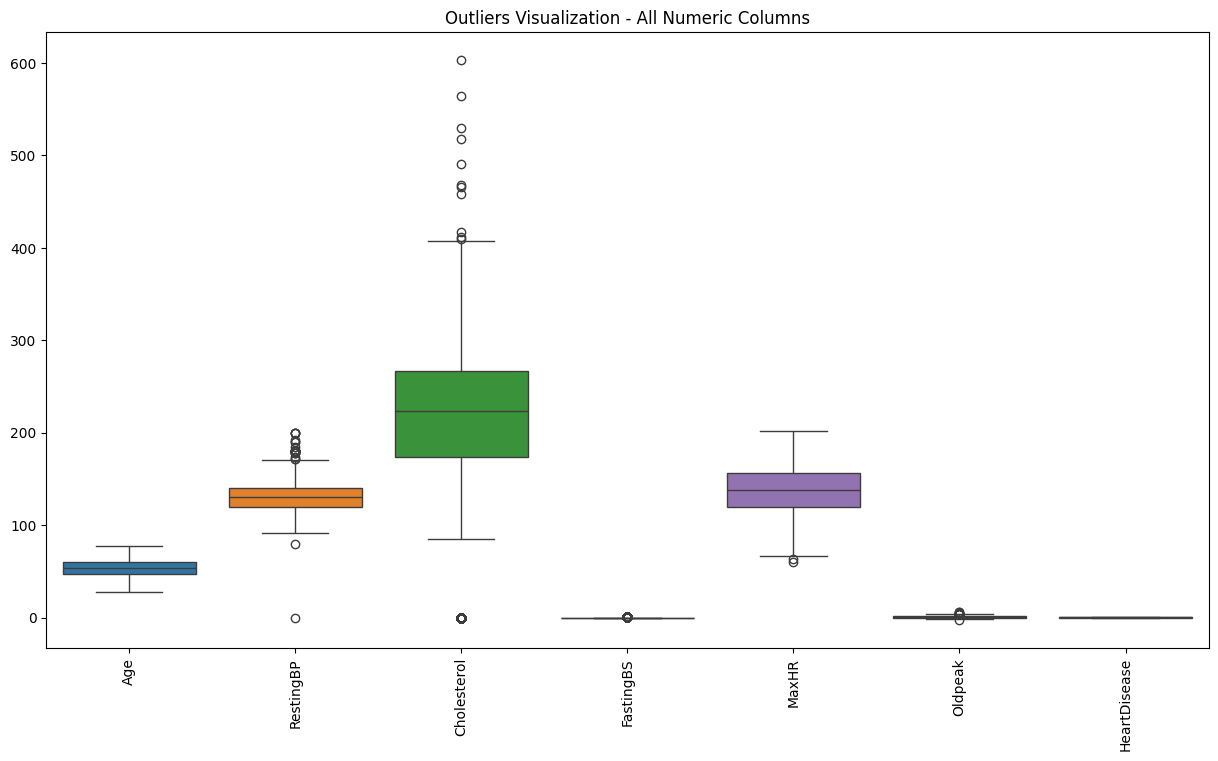

In [82]:
#visualizing the outliers
numeric_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(15,8))
sns.boxplot(data=df[numeric_cols])
plt.title("Outliers Visualization - All Numeric Columns")
plt.xticks(rotation=90)
plt.show()

In [83]:
#Detecting the outliers
def detect_outliers(df):
    outlier_indices = {}
    for col in df.select_dtypes(include=np.number).columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        outlier_indices[col] = outliers.index.tolist()
    return outlier_indices

outliers = detect_outliers(df)
print(outliers)

{'Age': [], 'RestingBP': [109, 123, 189, 190, 241, 274, 275, 278, 314, 365, 372, 399, 411, 423, 449, 475, 550, 585, 592, 673, 702, 725, 732, 759, 774, 780, 855, 880], 'Cholesterol': [28, 30, 69, 76, 103, 149, 250, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 421, 423, 424, 427, 428, 429, 430, 434, 435, 436, 437, 438, 439, 440, 441, 442, 446, 449, 450, 451, 453, 455, 456, 457, 458, 459, 461, 463, 464, 466, 467, 470, 471, 472, 4

In [84]:
#Treating the outliers
def treat_outliers(df):
    for col in df.select_dtypes(include=np.number).columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = np.where(df[col] < lower_bound, lower_bound,
                           np.where(df[col] > upper_bound, upper_bound, df[col]))
    return df

df_treated = treat_outliers(df.copy())

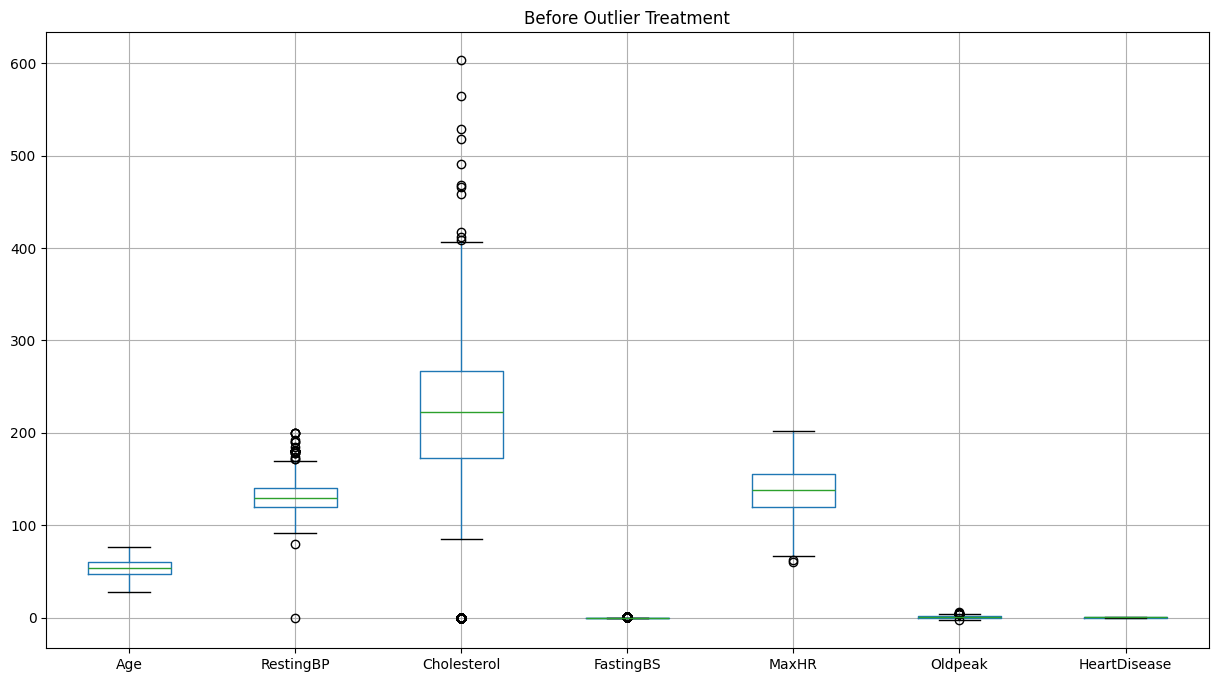

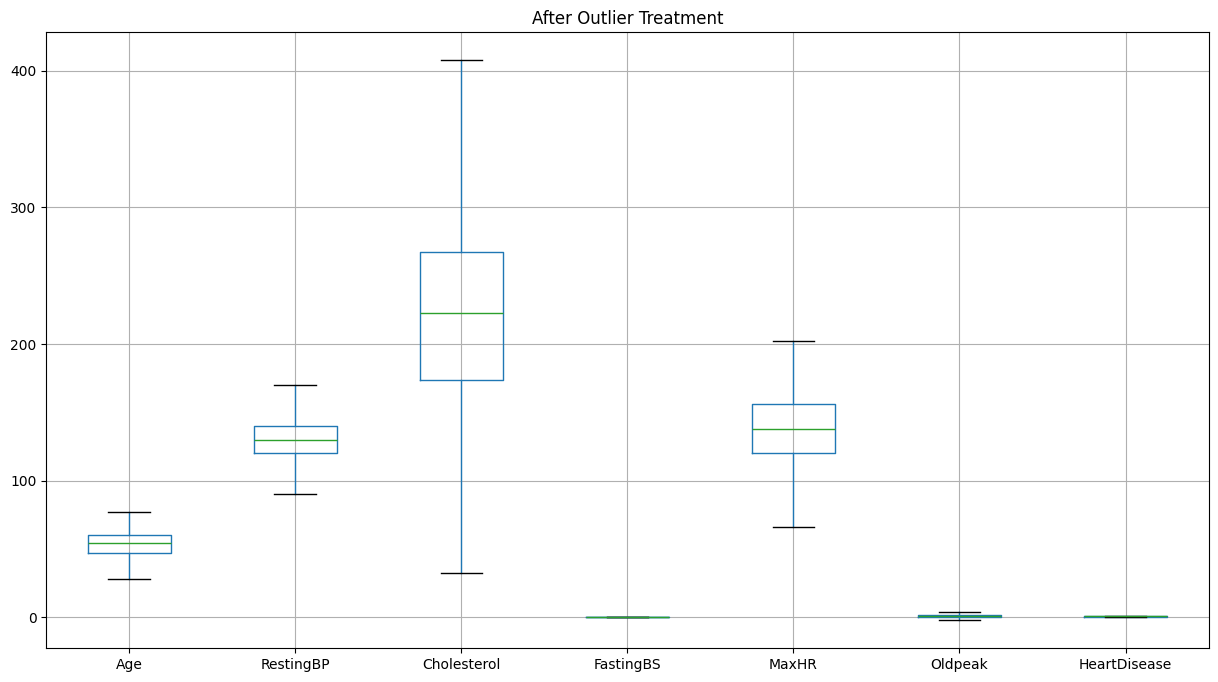

In [85]:
#Before and After oulier treatment
numeric_cols = df.select_dtypes(include=np.number).columns

# Before treatment
plt.figure(figsize=(15,8))
df[numeric_cols].boxplot()
plt.title("Before Outlier Treatment")
plt.show()

# After treatment
plt.figure(figsize=(15,8))
df_treated[numeric_cols].boxplot()
plt.title("After Outlier Treatment")
plt.show()

#Cleaning the data

we have detected few outliers in the columns like

*  Resting BP
*  chloestral

*  Fasting BP
*  MaxHR

*   old peak

Therefore we have removed the outliers successfully







In [86]:
#Converting the categoricl columns to numerical columns using one-hot encoding
df.select_dtypes(include = 'object').columns


Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='object')

In [87]:
df = pd.get_dummies(df, drop_first= True, dtype= int)

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   RestingBP          918 non-null    int64  
 2   Cholesterol        918 non-null    int64  
 3   FastingBS          918 non-null    int64  
 4   MaxHR              918 non-null    int64  
 5   Oldpeak            918 non-null    float64
 6   HeartDisease       918 non-null    int64  
 7   Sex_M              918 non-null    int64  
 8   ChestPainType_ATA  918 non-null    int64  
 9   ChestPainType_NAP  918 non-null    int64  
 10  ChestPainType_TA   918 non-null    int64  
 11  RestingECG_Normal  918 non-null    int64  
 12  RestingECG_ST      918 non-null    int64  
 13  ExerciseAngina_Y   918 non-null    int64  
 14  ST_Slope_Flat      918 non-null    int64  
 15  ST_Slope_Up        918 non-null    int64  
dtypes: float64(1), int64(15)
m

In [89]:
df['HeartDisease'].value_counts()

,count
HeartDisease,
1,508
0,410


In [90]:
df["HeartDisease"].value_counts(normalize = True)*100

,proportion
HeartDisease,
1,55.337691
0,44.662309


In [91]:
#splitting the data into X and y
from sklearn.model_selection import train_test_split
X = df.drop('HeartDisease', axis = 1)
y = df['HeartDisease'].astype(int)

In [92]:
# Splitting the dataset into train and test sets, then printing their shapes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y = df['HeartDisease'].map({'yes': 1, 'no': 0})
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (734, 15)
X_test shape: (184, 15)
y_train shape: (734,)
y_test shape: (184,)


In [93]:
print(df["HeartDisease"].value_counts(dropna = False))
print(df['HeartDisease'].isna().sum())

HeartDisease
1    508
0    410
Name: count, dtype: int64
0


In [94]:
print(df['HeartDisease'].unique())

[0 1]


In [95]:
print(df['HeartDisease'].astype(int))

0      0
1      1
2      0
3      1
4      0
      ..
913    1
914    1
915    1
916    1
917    0
Name: HeartDisease, Length: 918, dtype: int64


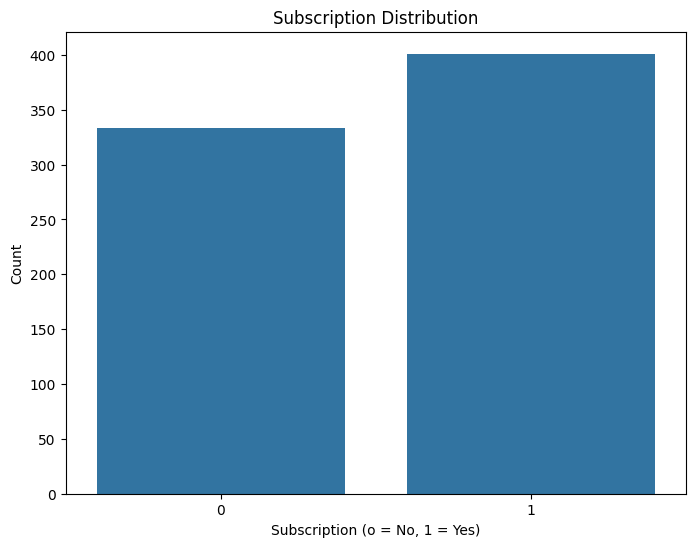

In [96]:
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train)

plt.title('Subscription Distribution')
plt.xlabel('Subscription (o = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

The above graph shows that the data has almost 50-50 percentage of people with heart disease and without but slightly there are more patients with heart disease

In [97]:
#Applying SMOTE technique to balance the imbalanced data
from imblearn.over_sampling import SMOTE
smote = SMOTE()
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [98]:
#Before and After smote technique
print(y_train.value_counts())
print(y_train_smote.value_counts())

HeartDisease
1    401
0    333
Name: count, dtype: int64
HeartDisease
0    401
1    401
Name: count, dtype: int64


#Approach
we have done with understanding the data and data analysis(EDA)
we have used smote technique to balance thw imbalanceed data

##boosting Techniques used


*   catboost
*   Xgboost

*   random forest
*   LGBM classifier

*   Adaclassifier etc







In [99]:
#Installing catboost
!pip install catboost

In [100]:
#Training the model using catboost
from catboost import CatBoostClassifier
model = CatBoostClassifier()
model.fit(X_train_smote, y_train_smote)

Learning rate set to 0.009376
0:	learn: 0.6845029	total: 6.39ms	remaining: 6.38s
1:	learn: 0.6769810	total: 8.46ms	remaining: 4.22s
2:	learn: 0.6692022	total: 10.4ms	remaining: 3.46s
3:	learn: 0.6619503	total: 11.7ms	remaining: 2.92s
4:	learn: 0.6541738	total: 13.5ms	remaining: 2.69s
5:	learn: 0.6454101	total: 15.4ms	remaining: 2.55s
6:	learn: 0.6369913	total: 17.8ms	remaining: 2.53s
7:	learn: 0.6312326	total: 19.1ms	remaining: 2.37s
8:	learn: 0.6239351	total: 20.9ms	remaining: 2.3s
9:	learn: 0.6163808	total: 22.6ms	remaining: 2.24s
10:	learn: 0.6089485	total: 24.4ms	remaining: 2.2s
11:	learn: 0.6019142	total: 26.3ms	remaining: 2.17s
12:	learn: 0.5957001	total: 28.1ms	remaining: 2.13s
13:	learn: 0.5890854	total: 29.9ms	remaining: 2.1s
14:	learn: 0.5836220	total: 31.6ms	remaining: 2.07s
15:	learn: 0.5777950	total: 33.3ms	remaining: 2.05s
16:	learn: 0.5718906	total: 35.1ms	remaining: 2.03s
17:	learn: 0.5664487	total: 37ms	remaining: 2.02s
18:	learn: 0.5606012	total: 38.8ms	remaining: 2s


CatBoostClassifier()

In [101]:
#predicting labels for test
from sklearn.metrics import classification_report, accuracy_score
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.84      0.84        77
           1       0.89      0.89      0.89       107

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184

0.8695652173913043


we have obtained 87% of the precision or accuracy  by using catboost

wjich means that the model is predicting correctly about 87%

In [102]:
#Hyper parameter tuning
from catboost import CatBoostClassifier
model1 = CatBoostClassifier(iterations = 200, depth = 6, learning_rate = 0.1, verbose = 0, random_seed = 42)
model1.fit(X_train_smote, y_train_smote)

CatBoostClassifier(depth=6, iterations=200, learning_rate=0.1, random_seed=42, verbose=0)

In [103]:
from sklearn.metrics import classification_report, accuracy_score
y_pred = model1.predict(X_test)
print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.86      0.84        77
           1       0.89      0.87      0.88       107

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.87      0.86      0.86       184

0.8641304347826086


we have also obtained 87% of accuracy after hyperparameter tuning in catboost

In [104]:
#installing scikit learn
!pip install scikit-learn

In [105]:
#1.Importing the decision making classifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
# 2. Initialize the AdaBoost Classifier
# By default, it uses DecisionTreeClassifier(max_depth=1) as the base estimator
model2 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,       # Number of weak learners to train
    learning_rate=1.0,     # Shrinks the contribution of each classifier
    random_state=42
)
# 3. Train the model
model.fit(X_train, y_train)
# 4. Evaluate performance
accuracy = model.score(X_test, y_test)
print(f"AdaBoost Test Accuracy: {accuracy:.4f}")

Learning rate set to 0.009028
0:	learn: 0.6860818	total: 9.72ms	remaining: 9.71s
1:	learn: 0.6795766	total: 14.1ms	remaining: 7.03s
2:	learn: 0.6725380	total: 18.2ms	remaining: 6.06s
3:	learn: 0.6668898	total: 21.2ms	remaining: 5.28s
4:	learn: 0.6607630	total: 23.6ms	remaining: 4.7s
5:	learn: 0.6550111	total: 24.8ms	remaining: 4.11s
6:	learn: 0.6478241	total: 29.2ms	remaining: 4.14s
7:	learn: 0.6414265	total: 37.8ms	remaining: 4.69s
8:	learn: 0.6343222	total: 46.3ms	remaining: 5.1s
9:	learn: 0.6291485	total: 51.9ms	remaining: 5.14s
10:	learn: 0.6248375	total: 60.2ms	remaining: 5.41s
11:	learn: 0.6200315	total: 67.4ms	remaining: 5.55s
12:	learn: 0.6131424	total: 81.2ms	remaining: 6.16s
13:	learn: 0.6076810	total: 87ms	remaining: 6.13s
14:	learn: 0.6018889	total: 93ms	remaining: 6.11s
15:	learn: 0.5975688	total: 98.7ms	remaining: 6.07s
16:	learn: 0.5928071	total: 104ms	remaining: 6.02s
17:	learn: 0.5881529	total: 110ms	remaining: 5.98s
18:	learn: 0.5848950	total: 115ms	remaining: 5.92s
1

After using the adaboost we have obtained around 88% of the accuracy

In [106]:
#installing xgboost
!pip install xgboost

In [107]:
from xgboost import XGBClassifier
model3 = XGBClassifier()
model3.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [108]:
from sklearn.metrics import classification_report, accuracy_score
y_pred = model3.predict(X_test)
print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85        77
           1       0.90      0.88      0.89       107

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184

0.8695652173913043


we have obtained around 87% by using the XGboost

In [109]:
!pip install lightgbm

In [110]:
from lightgbm import LGBMClassifier
model4 = LGBMClassifier()
model4.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 401, number of negative: 333
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000312 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 362
[LightGBM] [Info] Number of data points in the train set: 734, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.546322 -> initscore=0.185819
[LightGBM] [Info] Start training from score 0.185819
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

LGBMClassifier()

In [111]:
from sklearn.metrics import classification_report, accuracy_score
y_pred = model4.predict(X_test)
print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83        77
           1       0.88      0.87      0.87       107

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184

0.8532608695652174


we have obtained around 86% of the accuracy by using LGBM Boosting

In [112]:
# Real time testing

new_customer = X_test.iloc[0]

new_customer_df = pd.DataFrame([new_customer])

prediction = model1.predict(new_customer_df)

print(prediction)

[0]


In [113]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train_smote, y_train_smote)

RandomForestClassifier()

In [114]:
y_train_pred = model.predict(X_train_smote)
y_test_pred = model.predict(X_test)

In [115]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
print("Train Accuracy:", accuracy_score(y_train_smote, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

Train Accuracy: 1.0
Test Accuracy: 0.8586956521739131


In [117]:
# hyperparameters

from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50,100,200,300,500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, n_jobs = -1, scoring = 'f1')
grid_search.fit(X_train_smote, y_train_smote)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200, 300, 500]},
             scoring='f1')

we have obtained around 86% of the accuracy by using random forest

#Dataset Overview
Rows: 918 patient records (complete, no missing values).

Columns: 11 features + 1 target (HeartDisease).

Target: Binary classification → 1 (heart disease), 0 (normal).

##Key Insights
Age Factor

Risk of heart disease increases with age.

Older patients show higher prevalence of positive cases.

Chest Pain Type

Strong predictor: patients with Typical Angina (TA) or Asymptomatic (ASY) chest pain types are more likely to have heart disease.

Cholesterol & RestingBP

Elevated cholesterol and blood pressure are classic cardiovascular risk factors.

Patients with higher values tend to fall into the heart disease class.

Exercise-Related Features

ExerciseAngina (Yes) and lower MaxHR are strongly associated with heart disease.

Indicates reduced exercise tolerance in affected patients.

ECG Features (Oldpeak & ST_Slope)

Abnormal ST depression (Oldpeak) and flat/downsloping ST segments are highly predictive of heart disease.

These features often rank among the top in CatBoost’s feature importance.

## Findings from Model Performance
Accuracy: ~86% - 87% with all the boosting techinique with hyperparameter tuning

Precision/Recall: Balanced across both classes (0.84–0.89).

Medical Relevance: Recall for class 1 (heart disease) is strong, meaning the model is good at catching positive cases — critical in healthcare.